# Neuron Lab 01: From Input Current to Action Potentials

An interactive introduction to single-neuron dynamics using Brian2.

## Objective

In this notebook, we simulate a single neuron and investigate how electrical input changes its membrane potential.

We will answer the following question:

> How does an input current cause a neuron to produce an action potential?

The simulation uses the **Leaky Integrate-and-Fire (LIF)** model, implemented with the Brian2 simulator.

In [1]:
!pip -q install brian2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 14.4 MB/s eta 0:00:00


In [2]:
import brian2 as b2

print(f"Brian2 version: {b2.__version__}")
print("Brian2 was installed successfully.")

Brian2 version: 2.10.1
Brian2 was installed successfully.


## The Leaky Integrate-and-Fire Model

The membrane potential is represented by the following equation:

$$
\tau \frac{dV}{dt} = V_{\mathrm{rest}} - V + R I(t)
$$

where:

- $V$ is the membrane potential,
- $V_{\mathrm{rest}}$ is the resting membrane potential,
- $\tau$ is the membrane time constant,
- $R$ is the membrane resistance,
- $I(t)$ is the input current.

A spike occurs when the membrane potential crosses a threshold value. After the spike, the membrane potential is reset.

## Why Does This Equation Describe a Neuron?

The Leaky Integrate-and-Fire model is based on a simple electrical approximation of the cell membrane.

A neuronal membrane behaves like two electrical components operating in parallel:

1. A **capacitor**, which stores electrical charge.
2. A **leak resistor**, which allows a small amount of ionic current to cross the membrane.

```text
Input current
     |
     +----> Capacitor: charge is stored and voltage changes
     |
     +----> Leak pathway: ions cross the membrane and pull voltage back
```

### 1. The Capacitive Current

The lipid membrane acts as an electrical insulator between the inside and outside of the neuron. Charges can accumulate on both sides of the membrane, creating a voltage difference.

The relationship between stored charge and voltage is:

$$
Q = CV
$$

where:

- $Q$ is stored electrical charge,
- $C$ is membrane capacitance,
- $V$ is membrane potential.

Current is the rate at which charge changes over time:

$$
I = \frac{dQ}{dt}
$$

Therefore, the capacitive current is:

$$
I_{\mathrm{capacitor}} = C \frac{dV}{dt}
$$

This means that changing the membrane voltage rapidly requires more current. A membrane with a larger capacitance changes its voltage more slowly for the same input current.

### 2. The Leak Current

Real neuronal membranes are not perfect insulators. Some ions continuously cross the membrane through leak channels.

The leak current follows Ohm's law:

$$
I_{\mathrm{leak}} = \frac{V - E_L}{R}
$$

where:

- $V$ is the current membrane potential,
- $E_L$ is the leak reversal potential,
- $R$ is membrane resistance.

The leak current always drives the membrane potential toward $E_L$.

```text
If V > E_L, the leak current pulls V downward.
If V = E_L, the leak current is zero.
If V < E_L, the leak current pulls V upward.
```

In this simplified model, $E_L$ is approximately equal to the resting membrane potential:

$$
E_L \approx V_{\mathrm{rest}}
$$

### 3. Combining Both Effects

The input current is divided between charging the membrane capacitor and flowing through the leak pathway:

$$
I(t) =
C\frac{dV}{dt}
+
\frac{V-E_L}{R}
$$

Rearranging this equation gives:

$$
RC\frac{dV}{dt}
=
E_L - V + RI(t)
$$

We define the membrane time constant as:

$$
\tau = RC
$$

Therefore:

$$
\tau \frac{dV}{dt}
=
V_{\mathrm{rest}} - V + RI(t)
$$

This is the Leaky Integrate-and-Fire membrane equation.

The equation describes voltage changes before a spike occurs. The spike threshold, voltage reset, and refractory period are additional simplified rules that represent neuronal firing.

In [3]:
import brian2 as b2
import matplotlib.pyplot as plt

# Clear any earlier simulations
b2.start_scope()

# Simulation time step
b2.defaultclock.dt = 0.1 * b2.ms

# Neuron parameters
v_rest = -65 * b2.mV
v_threshold = -50 * b2.mV
v_reset = -65 * b2.mV
tau = 10 * b2.ms
resistance = 100 * b2.Mohm

# Input current protocol:
# 0-50 ms: no current
# 50-100 ms: weak current
# 100-150 ms: strong current
# 150-200 ms: no current
stimulus = b2.TimedArray(
    [0, 0.05, 0.25, 0] * b2.nA,
    dt=50 * b2.ms
)

# Leaky Integrate-and-Fire membrane equation
equations = """
dv/dt = (v_rest - v + resistance * stimulus(t)) / tau : volt
"""

# Create one neuron
neuron = b2.NeuronGroup(
    1,
    equations,
    threshold="v > v_threshold",
    reset="v = v_reset",
    refractory=5 * b2.ms,
    method="euler",
    namespace={
        "v_rest": v_rest,
        "v_threshold": v_threshold,
        "v_reset": v_reset,
        "tau": tau,
        "resistance": resistance,
        "stimulus": stimulus,
    },
)

neuron.v = v_rest

# Record membrane voltage and spike times
voltage_monitor = b2.StateMonitor(neuron, "v", record=True)
spike_monitor = b2.SpikeMonitor(neuron)

# Run the simulation
b2.run(200 * b2.ms)

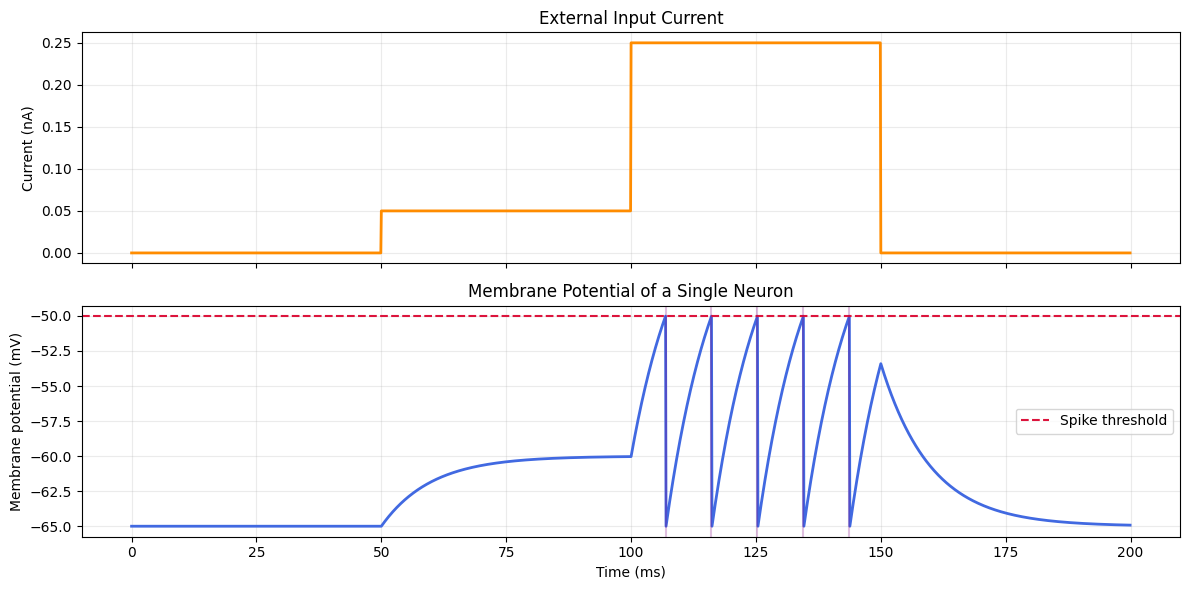

Number of spikes: 5
Spike times (ms): [106.9 116.1 125.3 134.5 143.7]


In [4]:
time_ms = voltage_monitor.t / b2.ms
input_current_na = stimulus(voltage_monitor.t) / b2.nA
membrane_voltage_mv = voltage_monitor.v[0] / b2.mV

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Input current plot
axes[0].plot(time_ms, input_current_na, color="darkorange", linewidth=2)
axes[0].set_title("External Input Current")
axes[0].set_ylabel("Current (nA)")
axes[0].grid(alpha=0.25)

# Membrane potential plot
axes[1].plot(time_ms, membrane_voltage_mv, color="royalblue", linewidth=2)
axes[1].axhline(
    v_threshold / b2.mV,
    color="crimson",
    linestyle="--",
    label="Spike threshold",
)

for spike_time in spike_monitor.t / b2.ms:
    axes[1].axvline(spike_time, color="purple", alpha=0.25)

axes[1].set_title("Membrane Potential of a Single Neuron")
axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Membrane potential (mV)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(f"Number of spikes: {spike_monitor.count[0]}")
print(f"Spike times (ms): {spike_monitor.t / b2.ms}")

## Interpretation

The neuron remains close to its resting potential when no current is applied.

A weak input current increases the membrane potential but may not be sufficient to reach the spike threshold.

A stronger input current drives the membrane potential above threshold, causing the neuron to emit spikes.

After each spike, the membrane potential is reset. This represents the basic computational process of neuronal firing:

$$
\text{Input current}
\rightarrow
\text{membrane voltage change}
\rightarrow
\text{threshold crossing}
\rightarrow
\text{spike}
$$

## Experiment: Temporal Summation and Coincidence Detection

In this experiment, two identical subthreshold input pulses are delivered to a neuron.

The total amount of input is identical in both conditions. The only difference is the time interval between the pulses.

- **Close pulses:** the second input arrives before the effect of the first input has leaked away.
- **Distant pulses:** the first input has mostly decayed before the second input arrives.

This experiment demonstrates temporal summation: neuronal firing depends not only on input strength, but also on input timing.

In [5]:
import numpy as np
import brian2 as b2
import matplotlib.pyplot as plt

# Start a fresh experiment
b2.start_scope()

b2.defaultclock.dt = 0.1 * b2.ms

# Neuron parameters
v_rest = -65 * b2.mV
v_threshold = -50 * b2.mV
v_reset = -65 * b2.mV
tau = 10 * b2.ms
resistance = 100 * b2.Mohm

# Experiment duration
duration_ms = 100

# Create two input patterns with identical pulses
close_values = np.zeros(duration_ms)
far_values = np.zeros(duration_ms)

# Two identical 0.20 nA pulses, each lasting 10 ms

# Close condition: pulses are separated by only 5 ms
close_values[20:30] = 0.20
close_values[35:45] = 0.20

# Far condition: pulses are separated by 40 ms
far_values[20:30] = 0.20
far_values[70:80] = 0.20

close_input = b2.TimedArray(close_values * b2.nA, dt=1 * b2.ms)
far_input = b2.TimedArray(far_values * b2.nA, dt=1 * b2.ms)

# LIF equation
equations = """
dv/dt = (v_rest - v + resistance * input_current(t)) / tau : volt
"""

def create_neuron(input_current):
    neuron = b2.NeuronGroup(
        1,
        equations,
        threshold="v > v_threshold",
        reset="v = v_reset",
        refractory=5 * b2.ms,
        method="euler",
        namespace={
            "v_rest": v_rest,
            "v_threshold": v_threshold,
            "v_reset": v_reset,
            "tau": tau,
            "resistance": resistance,
            "input_current": input_current,
        },
    )
    neuron.v = v_rest
    return neuron

# Create one neuron for each input condition
close_neuron = create_neuron(close_input)
far_neuron = create_neuron(far_input)

# Record voltage and spikes
close_voltage = b2.StateMonitor(close_neuron, "v", record=True)
far_voltage = b2.StateMonitor(far_neuron, "v", record=True)

close_spikes = b2.SpikeMonitor(close_neuron)
far_spikes = b2.SpikeMonitor(far_neuron)

# Run both neurons simultaneously
b2.run(duration_ms * b2.ms)

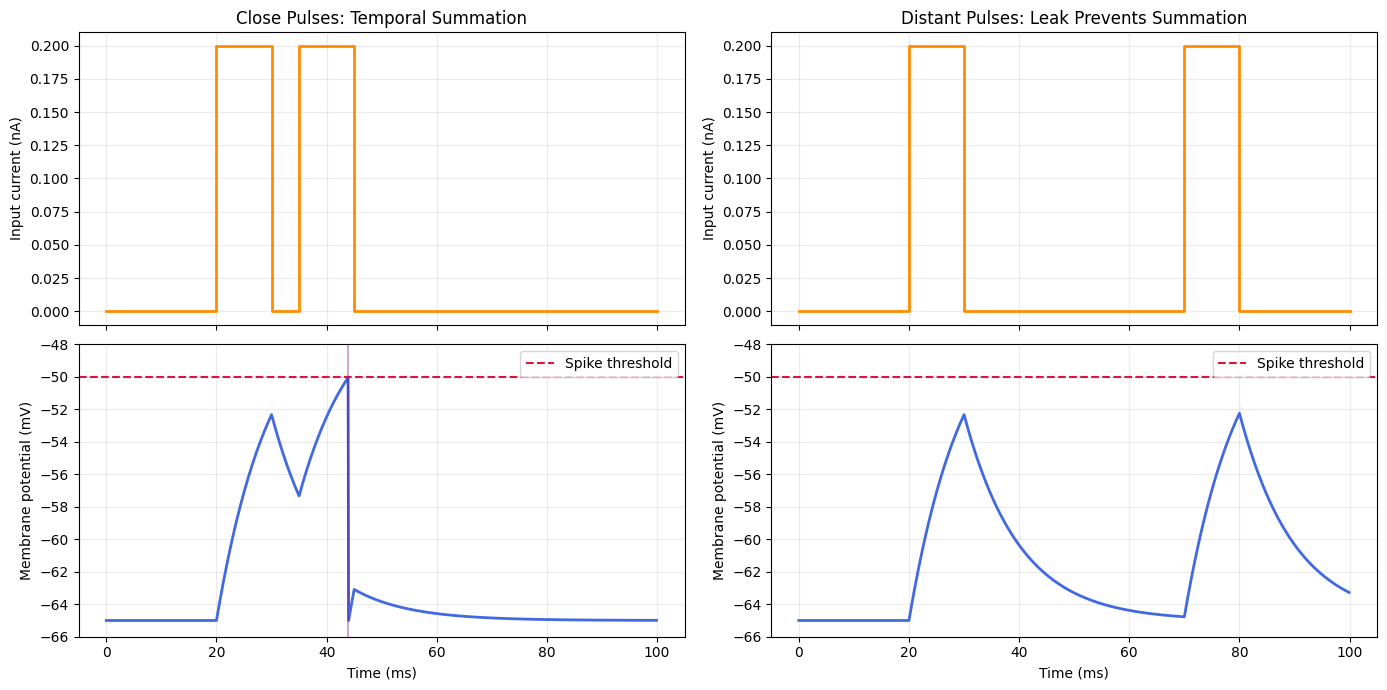

Close pulses: 1 spike(s), at [43.9] ms
Distant pulses: 0 spike(s), at [] ms


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex="col")

input_time = np.arange(duration_ms + 1)

def plot_case(column, input_values, voltage_monitor, spike_monitor, title):
    # Input current
    axes[0, column].step(
        input_time,
        np.append(input_values, 0),
        where="post",
        color="darkorange",
        linewidth=2,
    )
    axes[0, column].set_title(title)
    axes[0, column].set_ylabel("Input current (nA)")
    axes[0, column].grid(alpha=0.25)

    # Membrane voltage
    axes[1, column].plot(
        voltage_monitor.t / b2.ms,
        voltage_monitor.v[0] / b2.mV,
        color="royalblue",
        linewidth=2,
    )

    axes[1, column].axhline(
        v_threshold / b2.mV,
        color="crimson",
        linestyle="--",
        label="Spike threshold",
    )

    for spike_time in spike_monitor.t / b2.ms:
        axes[1, column].axvline(spike_time, color="purple", alpha=0.35)

    axes[1, column].set_xlabel("Time (ms)")
    axes[1, column].set_ylabel("Membrane potential (mV)")
    axes[1, column].set_ylim(-66, -48)
    axes[1, column].grid(alpha=0.25)
    axes[1, column].legend()

plot_case(
    0,
    close_values,
    close_voltage,
    close_spikes,
    "Close Pulses: Temporal Summation",
)

plot_case(
    1,
    far_values,
    far_voltage,
    far_spikes,
    "Distant Pulses: Leak Prevents Summation",
)

plt.tight_layout()
plt.show()

print(
    f"Close pulses: {close_spikes.count[0]} spike(s), "
    f"at {close_spikes.t / b2.ms} ms"
)

print(
    f"Distant pulses: {far_spikes.count[0]} spike(s), "
    f"at {far_spikes.t / b2.ms} ms"
)

## Conclusion: Timing Matters

Both conditions used the same number of input pulses, the same pulse amplitude, and the same total input current.

However, only the closely spaced pulses produced a spike.

This occurs because the membrane potential retains a short-lived memory of recent input. When the second pulse arrives quickly, it is added to the remaining depolarization caused by the first pulse.

When the pulses are far apart, the leak current returns the membrane potential toward rest before the second pulse arrives.

This demonstrates that a neuron can act as a temporal coincidence detector: it responds not only to how much input it receives, but also to when the input arrives.

## Experiment 2 — The Same Charge, a Different Outcome

Suppose we deliver the same total electrical charge to the same neuron in two different ways:

| Pulse | Current amplitude | Duration | Total charge |
|---|---:|---:|---:|
| Short and strong | $0.6\,\mathrm{nA}$ | $5\,\mathrm{ms}$ | $3\,\mathrm{nA\cdot ms}$ |
| Long and weak | $0.1\,\mathrm{nA}$ | $30\,\mathrm{ms}$ | $3\,\mathrm{nA\cdot ms}$ |

The total charge is the same because:

$$
Q = I \times T
$$

**Prediction:** Will both pulses produce the same number of spikes?

Write down your prediction before running the next cell.

In [7]:
import numpy as np
import brian2 as b2
import matplotlib.pyplot as plt

# Start a fresh simulation
b2.start_scope()

# Simulation settings
step_ms = 0.1
total_ms = 100
pulse_start_ms = 20

b2.defaultclock.dt = step_ms * b2.ms

# Use the same neuron parameters as the earlier experiments
sd_rest = -65 * b2.mV
sd_threshold = -50 * b2.mV
sd_reset = -65 * b2.mV
sd_tau = 10 * b2.ms
sd_resistance = 100 * b2.Mohm

# Pulse conditions: (amplitude in nA, duration in ms)
short_amplitude, short_duration = 0.6, 5
long_amplitude, long_duration = 0.1, 30

# Build a two-column current schedule:
# column 0 = short, strong pulse
# column 1 = long, weak pulse
number_of_steps = int(total_ms / step_ms)
current_values = np.zeros((number_of_steps, 2))

start_step = int(pulse_start_ms / step_ms)
short_end_step = int((pulse_start_ms + short_duration) / step_ms)
long_end_step = int((pulse_start_ms + long_duration) / step_ms)

current_values[start_step:short_end_step, 0] = short_amplitude
current_values[start_step:long_end_step, 1] = long_amplitude

sd_stimulus = b2.TimedArray(
    current_values * b2.nA,
    dt=step_ms * b2.ms
)

# Both neurons obey exactly the same LIF equation.
# Only their injected current differs.
sd_equations = """
dv/dt = (
    sd_rest - v + sd_resistance * sd_stimulus(t, i)
) / sd_tau : volt
"""

sd_neurons = b2.NeuronGroup(
    2,
    sd_equations,
    threshold="v > sd_threshold",
    reset="v = sd_reset",
    refractory=5 * b2.ms,
    method="euler",
    namespace={
        "sd_rest": sd_rest,
        "sd_threshold": sd_threshold,
        "sd_reset": sd_reset,
        "sd_tau": sd_tau,
        "sd_resistance": sd_resistance,
        "sd_stimulus": sd_stimulus,
    },
)

sd_neurons.v = sd_rest

sd_voltage = b2.StateMonitor(sd_neurons, "v", record=True)
sd_spikes = b2.SpikeMonitor(sd_neurons)

b2.run(total_ms * b2.ms)

short_charge = short_amplitude * short_duration
long_charge = long_amplitude * long_duration

print(f"Short-pulse charge: {short_charge:.1f} nA·ms")
print(f"Long-pulse charge:  {long_charge:.1f} nA·ms")
print(f"Short, strong pulse: {sd_spikes.count[0]} spike(s)")
print(f"Long, weak pulse:    {sd_spikes.count[1]} spike(s)")

Short-pulse charge: 3.0 nA·ms
Long-pulse charge:  3.0 nA·ms
Short, strong pulse: 1 spike(s)
Long, weak pulse:    0 spike(s)


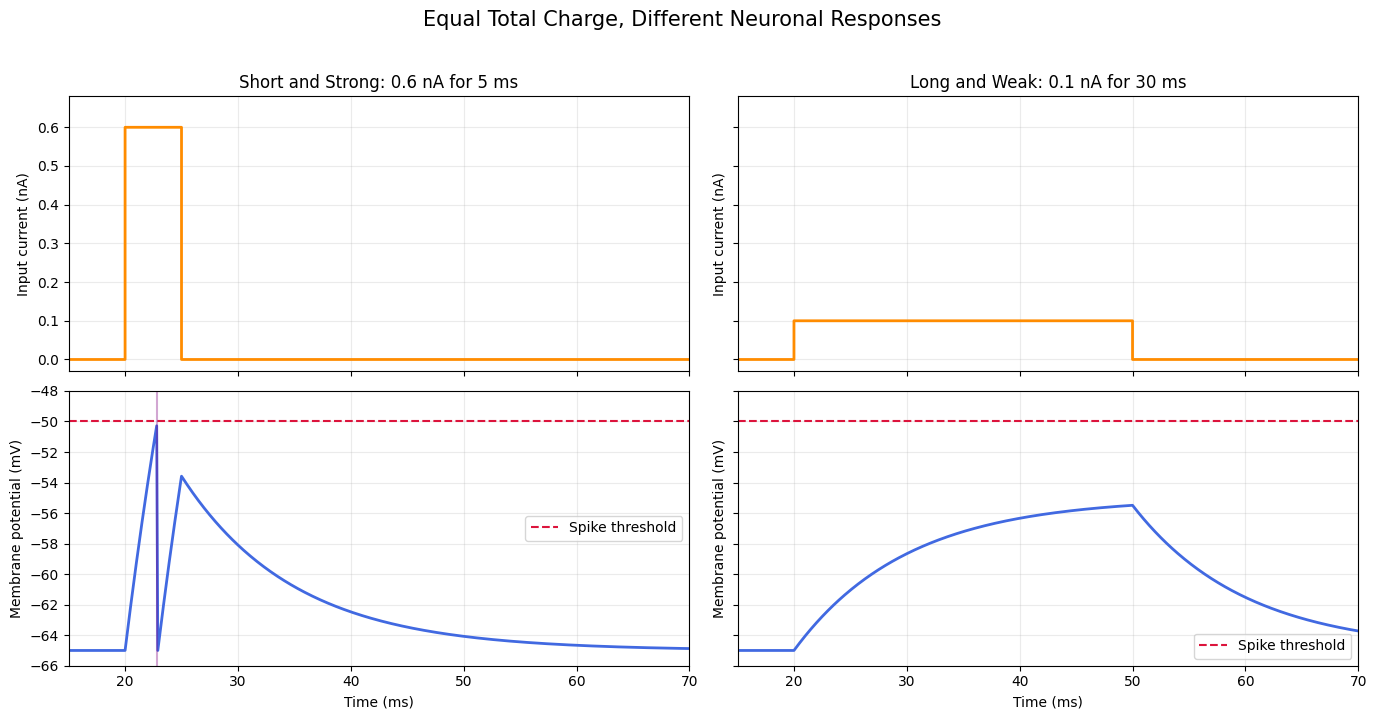

In [8]:
time_edges_ms = np.arange(number_of_steps + 1) * step_ms

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 7),
    sharex="col",
    sharey="row"
)

case_titles = [
    "Short and Strong: 0.6 nA for 5 ms",
    "Long and Weak: 0.1 nA for 30 ms",
]

for neuron_index in range(2):
    # Input current
    axes[0, neuron_index].step(
        time_edges_ms,
        np.append(current_values[:, neuron_index], 0),
        where="post",
        color="darkorange",
        linewidth=2,
    )
    axes[0, neuron_index].set_title(case_titles[neuron_index])
    axes[0, neuron_index].set_ylabel("Input current (nA)")
    axes[0, neuron_index].set_ylim(-0.03, 0.68)
    axes[0, neuron_index].grid(alpha=0.25)

    # Membrane potential
    axes[1, neuron_index].plot(
        sd_voltage.t / b2.ms,
        sd_voltage.v[neuron_index] / b2.mV,
        color="royalblue",
        linewidth=2,
    )
    axes[1, neuron_index].axhline(
        sd_threshold / b2.mV,
        color="crimson",
        linestyle="--",
        label="Spike threshold",
    )

    spike_times_ms = (
        sd_spikes.t[sd_spikes.i == neuron_index] / b2.ms
    )

    for spike_time in spike_times_ms:
        axes[1, neuron_index].axvline(
            spike_time,
            color="purple",
            alpha=0.35,
        )

    axes[1, neuron_index].set_xlabel("Time (ms)")
    axes[1, neuron_index].set_ylabel("Membrane potential (mV)")
    axes[1, neuron_index].set_xlim(15, 70)
    axes[1, neuron_index].set_ylim(-66, -48)
    axes[1, neuron_index].legend()
    axes[1, neuron_index].grid(alpha=0.25)

fig.suptitle(
    "Equal Total Charge, Different Neuronal Responses",
    fontsize=15,
    y=1.02,
)
plt.tight_layout()
plt.show()

## Why Did Equal Charge Produce Different Results?

The membrane does not store all incoming charge indefinitely. While current enters the neuron, some of its effect is continuously lost through the leak pathway.

For a constant current applied to a resting LIF neuron, the voltage *before any spike or reset* follows:

$$
V(T) =
V_{\mathrm{rest}}
+
RI\left(1-e^{-T/\tau}\right)
$$

For the long, weak pulse, the voltage can approach only:

$$
V_{\infty}
=
V_{\mathrm{rest}} + RI
=
-65\,\mathrm{mV} + 10\,\mathrm{mV}
=
-55\,\mathrm{mV}
$$

That is still below the spike threshold of $-50\,\mathrm{mV}$. Extending this weak pulse even further would not make this ideal LIF neuron spike.

The short, strong pulse pushes the voltage upward much faster. It crosses the threshold before the pulse ends, producing a spike.

> **Key observation:** Equal total charge does not guarantee an equal response. Current strength and pulse duration interact with the membrane's leak and time constant.

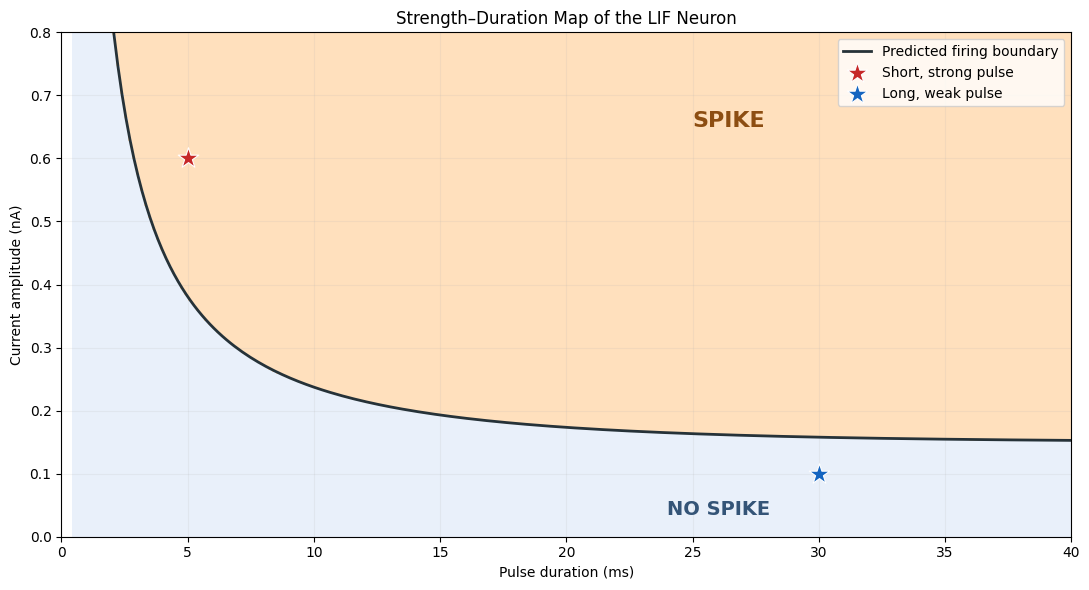

Long-duration current threshold (rheobase): 0.15 nA


In [9]:
from matplotlib.colors import ListedColormap

pulse_durations_ms = np.linspace(0.5, 40, 250)
pulse_currents_na = np.linspace(0, 0.8, 250)

duration_grid, current_grid = np.meshgrid(
    pulse_durations_ms,
    pulse_currents_na,
)

# Convert R × current from nA to mV
gain_mv_per_na = float(
    (sd_resistance * b2.nA) / b2.mV
)

rest_mv = float(sd_rest / b2.mV)
threshold_mv = float(sd_threshold / b2.mV)
tau_ms = float(sd_tau / b2.ms)

# Predicted voltage at the end of a pulse, before any spike/reset
predicted_voltage_mv = (
    rest_mv
    + gain_mv_per_na
    * current_grid
    * (1 - np.exp(-duration_grid / tau_ms))
)

predicted_spike = predicted_voltage_mv >= threshold_mv

# Analytic boundary between spike and no-spike regions
minimum_current_na = (
    (threshold_mv - rest_mv)
    / (
        gain_mv_per_na
        * (1 - np.exp(-pulse_durations_ms / tau_ms))
    )
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.pcolormesh(
    duration_grid,
    current_grid,
    predicted_spike.astype(int),
    shading="auto",
    cmap=ListedColormap(["#e9f0fa", "#ffe0bd"]),
)

ax.plot(
    pulse_durations_ms,
    minimum_current_na,
    color="#263238",
    linewidth=2,
    label="Predicted firing boundary",
)

ax.scatter(
    [short_duration],
    [short_amplitude],
    color="#c62828",
    marker="*",
    s=240,
    edgecolor="white",
    linewidth=0.8,
    label="Short, strong pulse",
    zorder=5,
)

ax.scatter(
    [long_duration],
    [long_amplitude],
    color="#1565c0",
    marker="*",
    s=240,
    edgecolor="white",
    linewidth=0.8,
    label="Long, weak pulse",
    zorder=5,
)

ax.text(25, 0.65, "SPIKE", fontsize=16, weight="bold", color="#8d4e12")
ax.text(24, 0.035, "NO SPIKE", fontsize=14, weight="bold", color="#345477")

ax.set_xlim(0, 40)
ax.set_ylim(0, 0.8)
ax.set_xlabel("Pulse duration (ms)")
ax.set_ylabel("Current amplitude (nA)")
ax.set_title("Strength–Duration Map of the LIF Neuron")
ax.legend(loc="upper right")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

rheobase_na = (threshold_mv - rest_mv) / gain_mv_per_na
print(f"Long-duration current threshold (rheobase): {rheobase_na:.2f} nA")

## What Did We Learn?

We gave the same total electrical charge to two identical LIF neurons. One fired; the other remained silent.

The difference came from the timing of charge delivery. A strong, brief pulse raised the membrane potential past threshold before the leak could counteract it. A weaker pulse delivered the same charge more slowly, allowing the leak to oppose the voltage change throughout the stimulation.

Together with the previous temporal-summation experiment, this gives us two important observations:

1. **Input timing matters:** closely spaced inputs can combine before their effects decay.
2. **Input delivery rate matters:** equal total charge can produce different outcomes.

The strength–duration curve maps the boundary between firing and silence for this simplified neuron. Similar questions arise in real electrical stimulation of nerves, although real tissue, electrodes, axons, and ion channels add important complexity.

### Model limitation

This notebook uses injected current and a Leaky Integrate-and-Fire neuron. Its spikes are threshold events followed by resets; it does not simulate the sodium and potassium currents that shape a biological action potential.

### Further reading

- [Brian2 documentation — time-varying inputs](https://brian2.readthedocs.io/en/stable/user/input.html)
- [Strength–duration relationships in neural stimulation](https://pubmed.ncbi.nlm.nih.gov/22516015/)

## Experiment 3 — Can a Neuron Adapt to a Constant Input?

In the previous experiments, we changed the input and observed a change in the neuron's response.

Now we will keep the input constant and ask a different question:

> Can a neuron's response change even when the input does not?

We will compare two otherwise identical neurons:

- **Regular LIF neuron:** every spike resets its voltage, but has no additional lasting effect.
- **Adapting neuron:** every spike also creates a temporary opposing current that gradually fades.

Both neurons receive the same current. After the first stimulation, we allow them to rest and then apply the same current again.

**Before running the experiment, predict:**

1. Will both neurons maintain a constant firing rhythm?
2. What will happen to the adapting neuron after a period of rest?

In [12]:
import numpy as np
import brian2 as b2
import matplotlib.pyplot as plt

b2.start_scope()

# Simulation settings
adapt_dt_ms = 0.1
adapt_total_ms = 1250
b2.defaultclock.dt = adapt_dt_ms * b2.ms

# Membrane properties: identical for both neurons
adapt_rest = -65 * b2.mV
adapt_threshold = -50 * b2.mV
adapt_reset = -65 * b2.mV
adapt_tau_m = 10 * b2.ms
adapt_resistance = 100 * b2.Mohm

# How quickly the adaptation effect fades
adapt_tau_w = 120 * b2.ms

# Current schedule:
# 0–50 ms:       rest
# 50–450 ms:     constant current
# 450–950 ms:    recovery period
# 950–1150 ms:   the same constant current again
# 1150–1250 ms:  rest
adapt_steps = int(adapt_total_ms / adapt_dt_ms)
adapt_current_values = np.zeros(adapt_steps)

adapt_current_values[
    int(50 / adapt_dt_ms):int(450 / adapt_dt_ms)
] = 0.30

adapt_current_values[
    int(950 / adapt_dt_ms):int(1150 / adapt_dt_ms)
] = 0.30

adapt_stimulus = b2.TimedArray(
    adapt_current_values * b2.nA,
    dt=adapt_dt_ms * b2.ms,
)

# w is an opposing current. It decays between spikes.
# Each spike increases w by that neuron's adaptation_step.
adapt_equations = """
dv/dt = (
    adapt_rest - v
    + adapt_resistance * (adapt_stimulus(t) - w)
) / adapt_tau_m : volt

dw/dt = -w / adapt_tau_w : amp
adaptation_step : amp
"""

adapt_neurons = b2.NeuronGroup(
    2,
    adapt_equations,
    threshold="v > adapt_threshold",
    reset="""
    v = adapt_reset
    w += adaptation_step
    """,
    refractory=5 * b2.ms,
    method="euler",
    namespace={
        "adapt_rest": adapt_rest,
        "adapt_threshold": adapt_threshold,
        "adapt_reset": adapt_reset,
        "adapt_tau_m": adapt_tau_m,
        "adapt_tau_w": adapt_tau_w,
        "adapt_resistance": adapt_resistance,
        "adapt_stimulus": adapt_stimulus,
    },
)

# Neuron 0 has no adaptation.
# Neuron 1 gains 0.05 nA of opposing current after each spike.
adapt_neurons.adaptation_step = np.array([0, 0.05]) * b2.nA
adapt_neurons.v = adapt_rest
adapt_neurons.w = 0 * b2.nA

adapt_monitor = b2.StateMonitor(
    adapt_neurons,
    ["v", "w"],
    record=True,
)
adapt_spikes = b2.SpikeMonitor(adapt_neurons)

b2.run(adapt_total_ms * b2.ms)

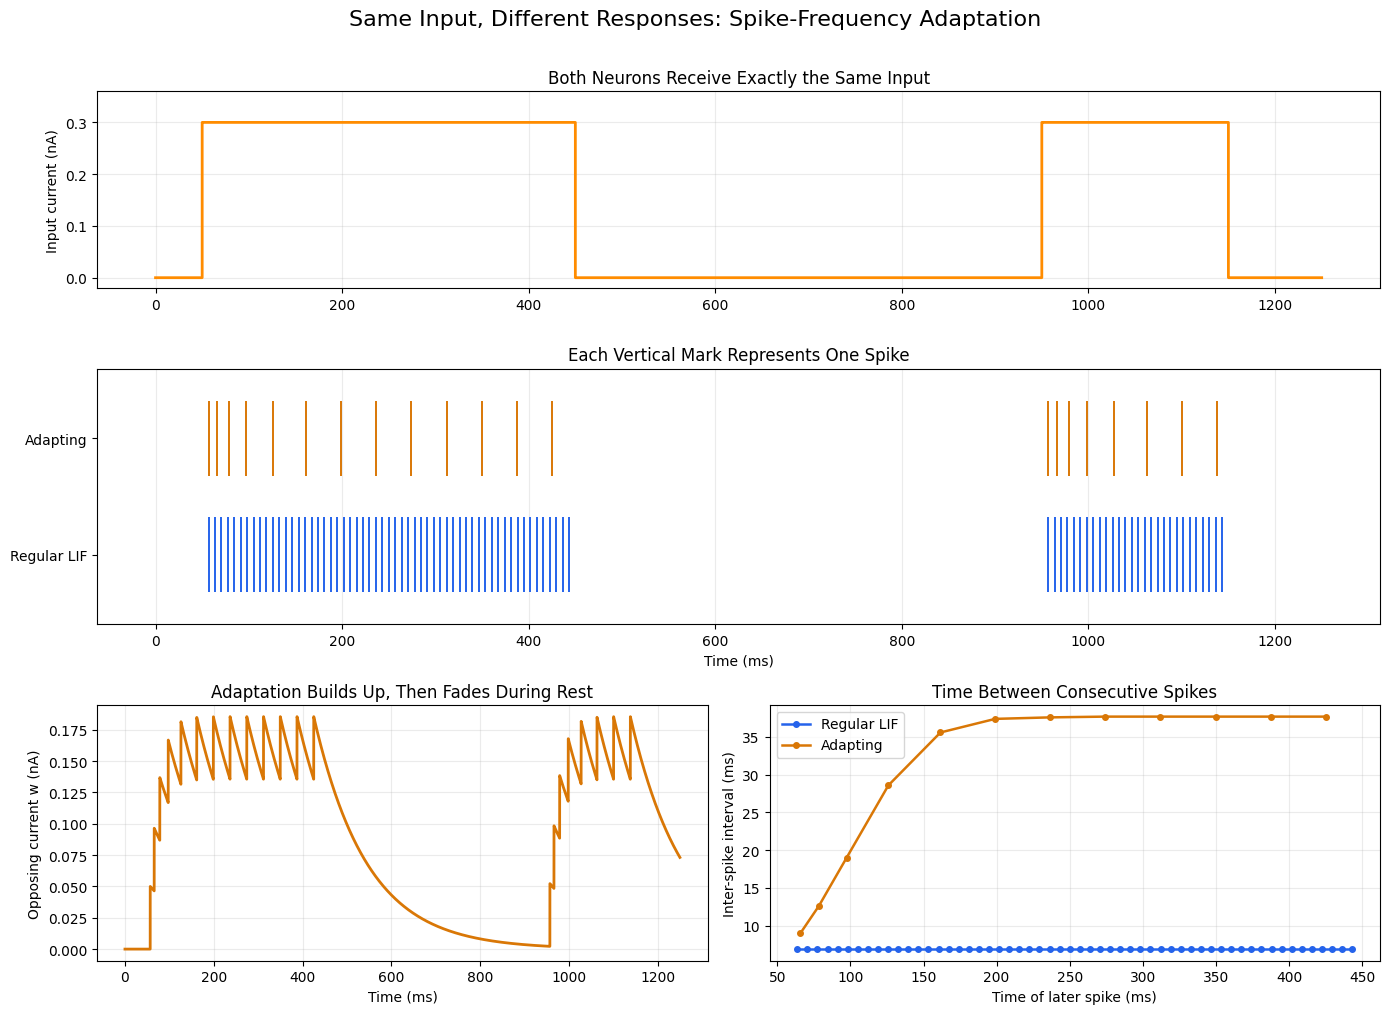

In [13]:
from matplotlib.gridspec import GridSpec

regular_color = "#2563eb"
adapting_color = "#d97706"

fig = plt.figure(figsize=(14, 10))
grid = GridSpec(3, 2, figure=fig, height_ratios=[1, 1.3, 1.3])

ax_input = fig.add_subplot(grid[0, :])
ax_spikes = fig.add_subplot(grid[1, :], sharex=ax_input)
ax_adaptation = fig.add_subplot(grid[2, 0])
ax_intervals = fig.add_subplot(grid[2, 1])

# 1. Identical input current for both neurons
adapt_time_edges = np.arange(adapt_steps + 1) * adapt_dt_ms

ax_input.step(
    adapt_time_edges,
    np.append(adapt_current_values, 0),
    where="post",
    color="darkorange",
    linewidth=2,
)
ax_input.set_title("Both Neurons Receive Exactly the Same Input")
ax_input.set_ylabel("Input current (nA)")
ax_input.set_ylim(-0.02, 0.36)
ax_input.grid(alpha=0.25)

# 2. Spike times
for neuron_index, row, color in [
    (0, 0, regular_color),
    (1, 1, adapting_color),
]:
    spike_times_ms = np.asarray(
        adapt_spikes.t[adapt_spikes.i == neuron_index] / b2.ms
    )
    ax_spikes.vlines(
        spike_times_ms,
        row - 0.32,
        row + 0.32,
        color=color,
        linewidth=1.4,
    )

ax_spikes.set_yticks([0, 1])
ax_spikes.set_yticklabels(["Regular LIF", "Adapting"])
ax_spikes.set_ylim(-0.6, 1.6)
ax_spikes.set_xlabel("Time (ms)")
ax_spikes.set_title("Each Vertical Mark Represents One Spike")
ax_spikes.grid(axis="x", alpha=0.25)

# 3. The temporary opposing current
ax_adaptation.plot(
    adapt_monitor.t / b2.ms,
    adapt_monitor.w[1] / b2.nA,
    color=adapting_color,
    linewidth=2,
)
ax_adaptation.set_title("Adaptation Builds Up, Then Fades During Rest")
ax_adaptation.set_xlabel("Time (ms)")
ax_adaptation.set_ylabel("Opposing current w (nA)")
ax_adaptation.grid(alpha=0.25)

# 4. Spacing between spikes during the first stimulation
for neuron_index, label, color in [
    (0, "Regular LIF", regular_color),
    (1, "Adapting", adapting_color),
]:
    spike_times_ms = np.asarray(
        adapt_spikes.t[adapt_spikes.i == neuron_index] / b2.ms
    )
    first_stimulation_spikes = spike_times_ms[
        (spike_times_ms >= 50) & (spike_times_ms < 450)
    ]

    ax_intervals.plot(
        first_stimulation_spikes[1:],
        np.diff(first_stimulation_spikes),
        "o-",
        markersize=4,
        linewidth=1.8,
        color=color,
        label=label,
    )

ax_intervals.set_title("Time Between Consecutive Spikes")
ax_intervals.set_xlabel("Time of later spike (ms)")
ax_intervals.set_ylabel("Inter-spike interval (ms)")
ax_intervals.legend()
ax_intervals.grid(alpha=0.25)

fig.suptitle(
    "Same Input, Different Responses: Spike-Frequency Adaptation",
    fontsize=16,
    y=1.01,
)
plt.tight_layout()
plt.show()

In [14]:
def spikes_between(neuron_index, start_ms, end_ms):
    times_ms = np.asarray(
        adapt_spikes.t[adapt_spikes.i == neuron_index] / b2.ms
    )
    return int(np.sum((times_ms >= start_ms) & (times_ms < end_ms)))

print("Spike counts in equally long, 100 ms windows:\n")

for neuron_index, name in [
    (0, "Regular LIF"),
    (1, "Adapting"),
]:
    early = spikes_between(neuron_index, 50, 150)
    late = spikes_between(neuron_index, 350, 450)
    after_rest = spikes_between(neuron_index, 950, 1050)

    print(name)
    print(f"  Start of first stimulation: {early} spikes")
    print(f"  End of first stimulation:   {late} spikes")
    print(f"  After a period of rest:     {after_rest} spikes\n")

Spike counts in equally long, 100 ms windows:

Regular LIF
  Start of first stimulation: 14 spikes
  End of first stimulation:   14 spikes
  After a period of rest:     14 spikes

Adapting
  Start of first stimulation: 5 spikes
  End of first stimulation:   2 spikes
  After a period of rest:     5 spikes



## What Changed Inside the Neuron?

The external input was identical for both neurons. The difference was an internal variable, $w$, representing a temporary current that opposes excitation.

$$
\tau_m \frac{dV}{dt}
=
V_{\mathrm{rest}} - V + R\bigl(I(t)-w\bigr)
$$

Between spikes, $w$ gradually decays:

$$
\tau_w \frac{dw}{dt}=-w
$$

After every spike, $w$ increases by a small amount:

$$
w \leftarrow w+b
$$

For the regular neuron, $b=0$. For the adapting neuron, $b>0$.

As the adapting neuron fires, $w$ builds up. The effective input, $I(t)-w$, becomes smaller even though the external input remains constant. The neuron therefore fires less frequently.

During the rest period, $w$ fades. When the same input returns, the neuron initially responds more strongly again.

### Connection to everyday experience

Think about a steady sensation, such as the feeling of a watch on your wrist or a constant background sound. You may notice it strongly at first and less strongly later, even though the stimulus is still present.

This experiment demonstrates one cellular principle that can contribute to adaptation: a neuron's recent activity can change its response to ongoing input.

It does **not** claim that one adapting neuron fully explains conscious perception. Real sensory adaptation involves receptors, synapses, many neurons, and larger brain circuits.

### Try it yourself

Change `adapt_tau_w` from `120 * b2.ms` to `400 * b2.ms`, then rerun the simulation and plots.

**Prediction:** Will the neuron recover as fully during the 500 ms rest period? Why?